# A vortex on the annulus from the Schottky–Klein prime function

**Goal:** For $\rho=0.3$, construct

$$P(\zeta,\rho) = (1-\zeta)\prod_{n=1}^{\infty}(1-\rho^{2n}\zeta)(1-\rho^{2n}\zeta^{-1})$$

from **functional equations** and **analyticity** (Cauchy–Riemann).

$$P(\zeta^{-1},\rho) = -\zeta^{-1} P(\zeta,\rho), \qquad P(\rho^2\zeta,\rho) = -\zeta^{-1} P(\zeta,\rho).$$

**Gauge near $\zeta\to 1$:** On $| \zeta |$ close to $1$,

$$P(\zeta,\rho) \approx (1-\zeta)\,C, \qquad C = \prod_{n=1}^{\infty}(1-\rho^{2n})^2$$

(truncated at `NMAX_REF`). We also keep **$P(1)=0$** as an explicit anchor.

**Also:** at the end, three **prime-function conformal maps** from the Day~3 slides (annulus exercise).


In [31]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

RHO = 0.2
NMAX_REF = 40
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
pi = np.pi

device: cpu


## Reference: truncated infinite product

In [32]:
def P_ref(zeta, rho=RHO, nmax=NMAX_REF):
    zeta = np.asarray(zeta, dtype=np.complex128)
    p = 1.0 - zeta
    for n in range(1, nmax + 1):
        p *= (1.0 - rho ** (2 * n) * zeta) * (1.0 - rho ** (2 * n) / zeta)
    return p


def C_near_one(rho=RHO, nmax=NMAX_REF):
    # C = prod_{n>=1} (1 - rho^{2n})^2  (limit of P(z)/(1-z) as z -> 1)
    c = 1.0
    for n in range(1, nmax + 1):
        c *= (1.0 - rho ** (2 * n)) ** 2
    return c


C_LIMIT = C_near_one()

def omega(zeta,a):
    return -a/C_LIMIT*P_ref(zeta/a)

def w(zeta, a):
    # Image of a in the unit circle. For real a this is not conj(a).
    return 1 / (2 * pi * 1j) * np.log(
        omega(zeta, a) / (abs(a) * omega(zeta, 1 / np.conj(a)))
    )

Im w on |ζ|=1:  mean -4.780e-18, std 4.613e-17
Im w on |ζ|=ρ: mean 1.103e-01, std 6.371e-17


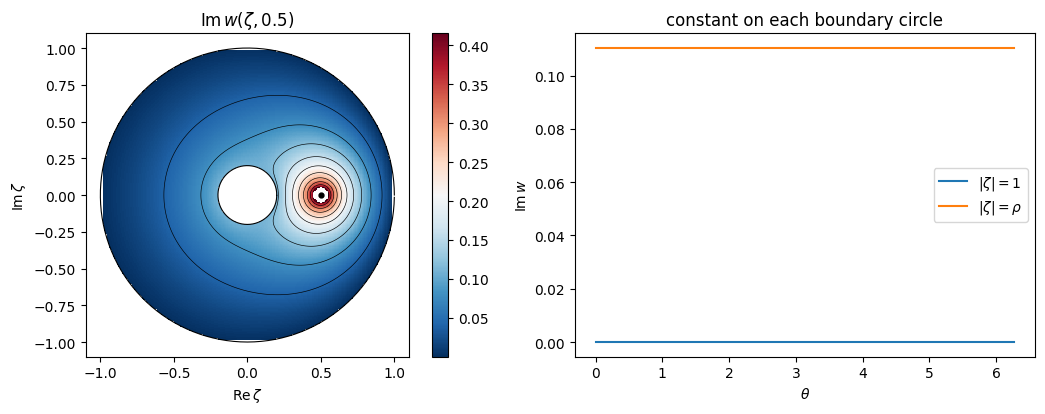

In [33]:
a_vort = 0.5
r_plot = 0.98
n = 220
x = np.linspace(-r_plot, r_plot, n)
y = np.linspace(-r_plot, r_plot, n)
X, Y = np.meshgrid(x, y)
Z = X + 1j * Y
mask = (np.abs(Z) >= RHO) & (np.abs(Z) <= 1.0) & (np.abs(Z - a_vort) > 0.05)

W = w(Z, a_vort)
imw = np.imag(W)
th = np.linspace(0, 2 * np.pi, 400, endpoint=False)
im_out = np.imag(w(np.exp(1j * th), a_vort))
im_in = np.imag(w(RHO * np.exp(1j * th), a_vort))
print(f"Im w on |ζ|=1:  mean {im_out.mean():.3e}, std {im_out.std():.3e}")
print(f"Im w on |ζ|=ρ: mean {im_in.mean():.3e}, std {im_in.std():.3e}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
data = np.ma.masked_where(~mask, imw)
im = ax[0].pcolormesh(X, Y, data, shading="auto", cmap="RdBu_r")
ax[0].contour(X, Y, data, levels=12, colors="k", linewidths=0.45)
ax[0].plot(np.cos(th), np.sin(th), "k-", lw=0.8)
ax[0].plot(RHO * np.cos(th), RHO * np.sin(th), "k-", lw=0.8)
ax[0].plot(a_vort, 0.0, "k.", ms=7)
ax[0].set_aspect("equal")
ax[0].set_title(r"$\mathrm{Im}\,w(\zeta,0.5)$")
ax[0].set_xlabel(r"$\mathrm{Re}\,\zeta$")
ax[0].set_ylabel(r"$\mathrm{Im}\,\zeta$")
plt.colorbar(im, ax=ax[0])
ax[1].plot(th, im_out, label=r"$|\zeta|=1$")
ax[1].plot(th, im_in, label=r"$|\zeta|=\rho$")
ax[1].set_xlabel(r"$\theta$")
ax[1].set_ylabel(r"$\mathrm{Im}\,w$")
ax[1].set_title("constant on each boundary circle")
ax[1].legend()
plt.tight_layout()
plt.show()

## Exercise: prime-function conformal maps (`day3.tex`)

On the annulus $\rho<|\zeta|<1$ (here $\rho=0.3$), visualise

1. $z = g(\zeta) = -\dfrac{P(\zeta,\rho)}{P(-\zeta,\rho)}$
2. $z = g(\zeta) = \dfrac{P(\zeta/a,\rho)\,P(\zeta\overline{a},\rho)}{P(\zeta/b,\rho)\,P(\zeta\overline{b},\rho)}$
3. $z = g(\zeta) = \dfrac{|b|}{|a|}\dfrac{P(\zeta/a,\rho)\,P(\zeta\overline{b},\rho)}{P(\zeta/b,\rho)\,P(\zeta\overline{a},\rho)}$

using the same truncated product `P_ref` as above (`NMAX_REF`). Points $a,b$ lie in the annulus.


a = 0.4378+0.3329j  (|a|=0.5500),  b = 0.0135+0.6499j  (|b|=0.6500)


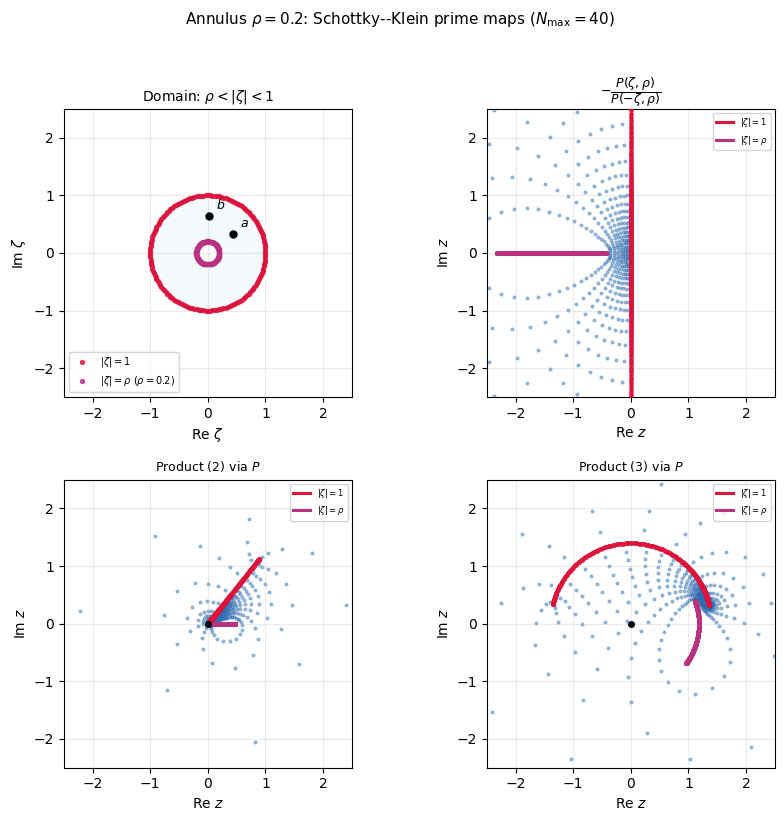

In [36]:
from pathlib import Path

PLOT_LIM = 2.5
# Sample points in the annulus (|z| > RHO and < 1)
A = 0.55 * np.exp(1j * 0.65)
B = 0.65 * np.exp(1j * 1.55)
assert RHO < np.abs(A) < 1 and RHO < np.abs(B) < 1

SAVE_FIGS = False
FIG_DIR = Path("../../teaching/text_pdf/fig").resolve()


def map_sk1(zeta, rho=RHO, nmax=NMAX_REF):
    zeta = np.asarray(zeta, dtype=np.complex128)
    return -P_ref(zeta, rho, nmax) / P_ref(-zeta, rho, nmax)


def map_sk2(zeta, a, b, rho=RHO, nmax=NMAX_REF):
    zeta = np.asarray(zeta, dtype=np.complex128)
    return (
        0.2*P_ref(zeta / a, rho, nmax)
        * P_ref(zeta * np.conj(a), rho, nmax)
        / (P_ref(zeta / b, rho, nmax) * P_ref(zeta * np.conj(b), rho, nmax))
    )


def map_sk3(zeta, a, b, rho=RHO, nmax=NMAX_REF):
    zeta = np.asarray(zeta, dtype=np.complex128)
    s = np.abs(b) / np.abs(a)
    return s * (
        P_ref(zeta / a, rho, nmax)
        * P_ref(zeta * np.conj(b), rho, nmax)
        / (P_ref(zeta / b, rho, nmax) * P_ref(zeta * np.conj(a), rho, nmax))
    )


def annulus_boundaries(rho=RHO, n=400):
    th = np.linspace(0, 2 * np.pi, n, endpoint=False)
    return rho * np.exp(1j * th), np.exp(1j * th)


def annulus_grid(rho=RHO, n_r=10, n_t=48):
    u = np.linspace(0, 1, n_r, endpoint=False)
    r = np.sqrt(rho**2 + u * (1.0 - rho**2))
    t = np.linspace(0, 2 * np.pi, n_t, endpoint=False)
    R, T = np.meshgrid(r, t, indexing="ij")
    return (R * np.exp(1j * T)).ravel()


def plot_annulus_panel(ax, a=A, b=B, n_boundary=160):
    th = np.linspace(0, 2 * np.pi, n_boundary, endpoint=False)
    ax.fill(np.cos(th), np.sin(th), color="#e8f4fc", alpha=0.45, zorder=0)
    ax.fill(RHO * np.cos(th), RHO * np.sin(th), color="white", zorder=1)
    ax.plot(np.cos(th), np.sin(th), "k-", lw=1.0, alpha=0.7, zorder=2)
    ax.plot(RHO * np.cos(th), RHO * np.sin(th), "k-", lw=1.0, alpha=0.7, zorder=2)
    z_out = np.exp(1j * th)
    z_in = RHO * z_out
    ax.scatter(z_out.real, z_out.imag, s=8, c="crimson", alpha=0.8, zorder=3, label=r"$|\zeta|=1$")
    ax.scatter(z_in.real, z_in.imag, s=8, c="#b83280", alpha=0.8, zorder=3, label=rf"$|\zeta|=\rho$ ($\rho={RHO}$)")
    for pt, lab in [(a, "$a$"), (b, "$b$")]:
        ax.plot(pt.real, pt.imag, "ko", ms=5, zorder=4)
        ax.annotate(lab, (pt.real, pt.imag), xytext=(5, 5), textcoords="offset points", fontsize=9)
    ax.set_aspect("equal")
    ax.set_xlim(-PLOT_LIM, PLOT_LIM)
    ax.set_ylim(-PLOT_LIM, PLOT_LIM)
    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=7, loc="lower left")
    ax.set_title(rf"Domain: $\rho<|\zeta|<1$", fontsize=10)
    ax.set_xlabel(r"Re $\zeta$")
    ax.set_ylabel(r"Im $\zeta$")


def _boundary_image(ax, zb, g, *, color, label, filled=True):
    w = g(zb)
    m = np.isfinite(w)
    if m.sum() < 4:
        return
    wr, wi = w[m].real, w[m].imag
    gap = np.hypot(wr[0] - wr[-1], wi[0] - wi[-1])
    span = max(np.hypot(wr.max() - wr.min(), wi.max() - wi.min()), 1e-9)
    if filled:
        if gap < 0.05 * span:
            ax.fill(wr, wi, color=color, alpha=0.22, zorder=2)
        else:
            eps = 0.035 * span
            ax.fill_between(wr, wi - eps, wi + eps, color=color, alpha=0.28, zorder=2)
    ax.plot(wr, wi, color=color, lw=2.2, zorder=3, label=label)
    ax.scatter(wr, wi, s=6, c=color, alpha=0.75, zorder=4)


def plot_map_image(ax, g, title, *, show_ab=True):
    z_in, z_out = annulus_boundaries()
    z_pts = annulus_grid()
    w_pts = g(z_pts)
    ok = np.isfinite(w_pts)
    ax.scatter(w_pts[ok].real, w_pts[ok].imag, s=4, alpha=0.4, c="#2b6cb0", zorder=1)
    _boundary_image(ax, z_out, g, color="crimson", label=r"$|\zeta|=1$")
    _boundary_image(ax, z_in, g, color="#b83280", label=rf"$|\zeta|=\rho$")
    if show_ab:
        for zp in [A, B]:
            w = g(np.array([zp]))[0]
            if np.isfinite(w):
                ax.plot(w.real, w.imag, "ko", ms=4, zorder=5)
    ax.set_aspect("equal")
    ax.set_xlim(-PLOT_LIM, PLOT_LIM)
    ax.set_ylim(-PLOT_LIM, PLOT_LIM)
    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=6, loc="upper right")
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(r"Re $z$")
    ax.set_ylabel(r"Im $z$")


print(f"a = {A:.4f}  (|a|={np.abs(A):.4f}),  b = {B:.4f}  (|b|={np.abs(B):.4f})")

fig, axes = plt.subplots(2, 2, figsize=(8.8, 8.0))
plot_annulus_panel(axes[0, 0])
plot_map_image(
    axes[0, 1],
    map_sk1,
    r"$-\dfrac{P(\zeta,\rho)}{P(-\zeta,\rho)}$",
    show_ab=False,
)
plot_map_image(axes[1, 0], lambda z: map_sk2(z, A, B), "Product (2) via $P$")
plot_map_image(axes[1, 1], lambda z: map_sk3(z, A, B), "Product (3) via $P$")
fig.suptitle(
    rf"Annulus $\rho={RHO}$: Schottky--Klein prime maps ($N_{{\max}}={NMAX_REF}$)",
    y=1.02,
    fontsize=11,
)
plt.tight_layout()
if SAVE_FIGS:
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    out = FIG_DIR / "day3_annulus_prime_maps_exercise.png"
    fig.savefig(out, dpi=160, bbox_inches="tight")
    print("saved", out)
plt.show()

